# First Naive RDD

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [3]:
# Or set to a specific large number (from my df)
pd.set_option('display.max_columns', 1163)

## Data Source (Education)
- https://unehistoireduconflitpolitique.fr/telecharger.html

#### Skill Share
(According to the mail from Prof. Loumeau)

**Skill Share** measures the proportion of highly educated individuals (holding a *baccalauréat* or higher) within a municipality.

$$\text{Skill Share} = \frac{\text{Educated Residents}}{\text{Total Residents}}$$

* **Example:** If a town has 1,000 residents and 200 hold a degree $\rightarrow \text{Skill Share} = 0.20 \text{ (20\%)}$.

---

#### Delta Skill Share
**Delta Skill Share** captures the temporal change in this educated fraction immediately surrounding an election cycle.

$$\Delta\text{Skill Share} = \text{Skill Share}_{\text{After Election}} - \text{Skill Share}_{\text{Before Election}}$$

* **Positive Value ($+0.03$):** The proportion of highly educated residents grew post-election.
* **Negative Value ($-0.03$):** The proportion of highly educated residents shrank post-election.

In [4]:
# Load education dat
df_edu = pd.read_csv("diplomescommunes.csv", dtype={"codecommune": str})

# Standardise commune code to 5 characters (leading zeros)
df_edu["codecommune"] = df_edu["codecommune"].str.zfill(5)

C:\Users\tobia\AppData\Local\Temp\ipykernel_25172\2857989072.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_edu = pd.read_csv("diplomescommunes.csv", dtype={"codecommune": str})


### Outcome Variable: Skill Share

| Column pattern | Meaning |
|---|---|
| `nodiph/f{year}` | Residents *without* any diploma (men/women) |
| `bach{year}/bacf{year}` | Residents with *baccalauréat* — high school level (men/women) |
| `suph{year}/supf{year}` | Residents with *university-level* education (men/women) |

**Skill share** = (bach + sup) / (nodip + bach + sup), for men and women combined.  
**Delta skill share** = skill share *after* election − skill share *before* election.  
A negative value means the educated share *shrunk* post-election.

In [5]:
# Helper functions
def compute_skill_share(df, year):
    """Fraction of residents with bac or higher, for a given census year."""
    educated = (df[f"bach{year}"] + df[f"suph{year}"] +    # men: bac + university
                df[f"bacf{year}"] + df[f"supf{year}"])     # women: bac + university
    total    = (educated +
                df[f"nodiph{year}"] + df[f"nodipf{year}"]) # add no-diploma residents
    return educated / total                                 # share between 0 and 1

def compute_total_pop(df, year):
    """Approximate total population from the three education tiers."""
    return (df[f"nodiph{year}"] + df[f"nodipf{year}"] +
            df[f"bach{year}"]   + df[f"bacf{year}"]   +
            df[f"suph{year}"]   + df[f"supf{year}"])

# Define election windows
# Each tuple: (election_year, pre_census_year, post_census_year)
# 2026 excluded — no post-election census available yet
windows = [
    (2008, 1999, 2009),
    (2014, 2009, 2014),
    (2020, 2014, 2019),
]

In [6]:
# Compute delta_skill_share with population filter
min_pop = 50   # communes below this threshold have not enough edu data to compute a reliable skill share

rows = []
for election_year, pre_y, post_y in windows:

    # Compute skill share at pre- and post-election census
    share_pre  = compute_skill_share(df_edu, pre_y)
    share_post = compute_skill_share(df_edu, post_y)

    # Delta = change in educated share around the election
    delta = share_post - share_pre

    # Null out communes too small in either census wave
    too_small = (compute_total_pop(df_edu, pre_y)  < min_pop) | \
                (compute_total_pop(df_edu, post_y) < min_pop)
    delta[too_small] = None

    # Build one df for this election year
    tmp = pd.DataFrame({
        "commune_id":        df_edu["codecommune"],
        "election_year":     election_year,
        "delta_skill_share": delta,
    })
    rows.append(tmp)

# Stack all election years into one long dataframe
df_outcome = pd.concat(rows, ignore_index=True)


In [7]:
df_outcome.head(3)

,commune_id,election_year,delta_skill_share
0,01001,2008,0.244295
1,01002,2008,0.268882
2,01003,2008,NaN


## Data Source (French Electoral outcomes)
- https://www.data.gouv.fr/datasets/donnees-des-elections-agregees

In [8]:
# Load the full candidats file
# Large file low_memory=False prevents dtype warnings
df_cand = pd.read_csv("candidats_results.csv", sep=";", encoding="latin-1", low_memory=False)

In [9]:
# Inspect all unique nuance codes
print(df_cand["nuance"].unique())

['LDVC' 'LDVD' nan 'LDIV' 'LRN' 'LDVG' 'LUG' 'LUD' 'LCOM' 'LUXD' 'LLR'
 'LFI' 'LEXD' 'LEXG' 'LREG' 'LUC' 'LUDR' 'LSOC' 'LUDI' 'LECO' 'LVEC'
 'LHOR' 'LREN' 'LMDM' 'LREC' 'LDSV' 'DXG' 'DVG' 'DIV' 'REG' 'ECO' 'NUP'
 'RDG' 'ENS' 'LR' 'DVC' 'DSV' 'DVD' 'UDI' 'REC' 'RN' 'DXD' 'REM' 'MDM'
 'FN' 'SOC' 'COM' 'FI' 'EXD' 'DLF' 'EXG' 'NC' 'LNC' 'LREM' 'LDLF' 'LGJ'
 'BC-UCD' 'BC-UG' 'BC-RN' 'BC-UD' 'BC-UGE' 'BC-UXD' 'BC-LR' 'BC-DVD'
 'BC-DVG' 'BC-DVC' 'BC-DIV' 'BC-RDG' 'BC-SOC' 'BC-COM' 'BC-UC' 'BC-REM'
 'BC-UCG' 'BC-ECO' 'BC-UDI' 'BC-MDM' 'BC-EXD' 'BC-FI' 'BC-EXG' 'BC-REG'
 'BC-DSV' 'BC-GJ' 'LAUT' 'LMAJ' 'LGC' 'LMC' 'LCMD' 'LFN' 'UG' 'UXD' 'HOR'
 'VEC' 'LENS' 'LRDG' 'LVEG' 'LFG' 'LUGE' 'LUCD' 'UMP' 'MNR' 'PREP' 'MPF'
 'LO' 'LCR' 'CPNT' 'RPF' 'PRG' 'UDF' 'DL' 'LCOP' 'RPR' 'MDC' 'UDFD' 'M-NC'
 'AUT' 'MNA' 'GAU' 'FRN' 'DTE' 'LDV' 'LDD' 'LPC' 'LXD' 'LUDF' 'LUMP' 'LPS'
 'LCP' 'LRG' 'LXG' 'LVE' 'LDG' 'LEC' 'LGA' 'LDR' 'PG' 'M' 'MODM' 'BOVE'
 'BUFF' 'SCHI' 'LAGU' 'VILL' 'VOYN' 'BAYR' 'BESA' 'ROYA' 'SARK'

#### Defining far right code names 
| Code    | Full Name                       | Years Active          |
|---------|---------------------------------|-----------------------|
| RN      | Rassemblement National          | 2020, 2026            |
| LRN     | Liste Rassemblement National    | 2020, 2026            |
| BC-RN   | Binôme/coalition RN             | 2020, 2026            |
| FN      | Front National                  | 2008, 2014            |
| FRN     | Front National                  | 2008, 2014, 2020      |
| LFN     | Liste Front National            | 2008, 2014            |
| BC-FN   | Binôme FN                       | 2014                  |
| EXD     | Extrême droite (generic)        | all years             |
| LEXD    | Liste extrême droite            | all years             |
| BC-EXD  | Binôme extrême droite           | 2014, 2020            |
| DXD     | Divers extrême droite           | all years             |
| LUXD    | Liste union extrême droite      | 2020, 2026            |
| UXD     | Union extrême droite            | all years             |
| BC-UXD  | Binôme union extrême droite     | 2014, 2020            |
| MNR     | Mouvement National Républicain  | 2008                  |

In [10]:
df_cand.head(3)

,id_election,id_brut_miom,code_departement,code_commune,code_bv,no_panneau,voix,ratio_voix_inscrits,ratio_voix_exprimes,nuance,sexe,nom,prenom,liste,libelle_abrege_liste,libelle_etendu_liste,nom_tete_liste,binome
0,2026_muni_t2,01160_0001,01,01160,0001,1.0,257,27.72,67.63,LDVC,M,PHILIPPS,Pierre-Marie,NaN,Une Energie Nouvelle Pour Ferney,Une Energie Nouvelle Pour Ferney,NaN,NaN
1,2026_muni_t2,01160_0002,01,01160,0002,1.0,311,25.79,65.47,LDVC,M,PHILIPPS,Pierre-Marie,NaN,Une Energie Nouvelle Pour Ferney,Une Energie Nouvelle Pour Ferney,NaN,NaN
2,2026_muni_t2,01160_0003,01,01160,0003,1.0,252,21.28,59.86,LDVC,M,PHILIPPS,Pierre-Marie,NaN,Une Energie Nouvelle Pour Ferney,Une Energie Nouvelle Pour Ferney,NaN,NaN


In [11]:
# Keep only the columns needed, drop the rest as the df is too big otherwise
df_slim = df_cand[[
    "id_election",    # year + round identifier
    "code_commune",   # municipality code
    "nuance",         # party affiliation
    "voix",           # vote count
]].copy()

In [12]:
df_slim.head(3)

,id_election,code_commune,nuance,voix
0,2026_muni_t2,01160,LDVC,257
1,2026_muni_t2,01160,LDVC,311
2,2026_muni_t2,01160,LDVC,252


In [13]:
# Parse year and round and add them as new columns
df_slim["election_year"] = df_slim["id_election"].str.split("_").str[0].astype(int)
df_slim["tour"]          = df_slim["id_election"].str.split("_").str[2]

# Keep only municipal elections
df_slim = df_slim[df_slim["id_election"].str.contains("muni")].drop(columns="id_election")

# Export, hence create a new file with only the columns needed for the RDD analysis
df_slim.to_csv("candidats_slim.csv", index=False)

In [14]:
df_slim.head(3)

,code_commune,nuance,voix,election_year,tour
0,01160,LDVC,257,2026,t2
1,01160,LDVC,311,2026,t2
2,01160,LDVC,252,2026,t2


In [15]:
# Define far-right nuance codes
far_right_nuances = [
    "RN", "LRN", "BC-RN",           # Rassemblement National (2020, 2026)
    "FN", "LFN", "BC-FN", "FRN"     # Front National (2008, 2014)
    "EXD", "LEXD", "BC-EXD",        # Extrême droite generic
    "DXD", "LUXD", "UXD", "BC-UXD", # Union / divers extrême droite
    "MNR",                          # Mégret splinter (2008)
]

# Possible that not all these nuances are present in the dataset, but we can still flag them if they are.

# Flag far-right rows
df_slim["is_far_right"] = df_slim["nuance"].isin(far_right_nuances)

In [16]:
# I do not use data from year 2026 right now
df_slim = df_slim[df_slim["election_year"] != 2026]

In [17]:
# Calculate share of far-right rows
far_right_share = df_slim["is_far_right"].mean() * 100
print(f"Share of far-right candidates: {far_right_share:.2f}%")

# Also show counts
print(f"\nCounts:")
print(df_slim["is_far_right"].value_counts())
print(f"\nTotal rows: {len(df_slim):,}")

Share of far-right candidates: 2.69%

Counts:
is_far_right
False    1424106
True       39424
Name: count, dtype: int64

Total rows: 1,463,530


In [18]:
df_slim.head(3)

,code_commune,nuance,voix,election_year,tour,is_far_right
6127200,01012,NC,0,2020,t2,False
6127201,01034,LDIV,202,2020,t2,False
6127202,01034,LDIV,235,2020,t2,False


In [19]:
df_slim.groupby('election_year')['is_far_right'].sum()

election_year
2008     5097
2014    20943
2020    13384
Name: is_far_right, dtype: int64

In [20]:
# Determine the decisive round per commune/year
#    (max tour number: 2 > 1)
df_slim['tour_num'] = df_slim['tour'].str.extract('(\d+)').astype(int)

# Get the highest tour number for each (commune, year)
decisive_rounds = (
    df_slim.groupby(['code_commune', 'election_year'])['tour_num']
    .max()
    .reset_index(name='decisive_tour')
)

# Keep only rows that belong to that decisive round
df_dec = df_slim.merge(decisive_rounds, on=['code_commune', 'election_year'], how='inner')
df_dec = df_dec[df_dec['tour_num'] == df_dec['decisive_tour']]

<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:3: SyntaxWarning: invalid escape sequence '\d'
C:\Users\tobia\AppData\Local\Temp\ipykernel_25172\2142661507.py:3: SyntaxWarning: invalid escape sequence '\d'
  df_slim['tour_num'] = df_slim['tour'].str.extract('(\d+)').astype(int)


In [21]:
# Identify the winner in each decisive round
#    (row with maximum voix)
winner_idx = df_dec.groupby(['code_commune', 'election_year'])['voix'].idxmax()
df_winners = df_dec.loc[winner_idx].copy()

In [22]:
df_winners.head(3)

,code_commune,nuance,voix,election_year,tour,is_far_right,tour_num,decisive_tour
771511,01001,NC,331,2014,t1,False,1,1
452703,01001,NC,267,2020,t1,False,1,1
771524,01002,NC,165,2014,t1,False,1,1


In [23]:
# ── Recreate treat column (1 = far-right won the decisive round, 0 = otherwise) ──
# df_winners should already contain only ONE row per commune x election_year
# (the winning list, selected via idxmax on voix). If so, is_far_right IS treat.
df_winners['treat'] = df_winners['is_far_right'].astype(int)

# Sanity check: one row per commune x election_year, and reasonable win count
print(df_winners.groupby(['code_commune', 'election_year']).size().max())  # should be 1
print(df_winners['treat'].sum())  # should match your earlier count (26)

1
26


When does a winner get <50%?

In French municipal elections, when 3+ lists contest the decisive round, votes split across them. The winner only needs a plurality (most votes), not an absolute majority (>50%). Example: three lists get 40%/35%/25% — the 40% list wins despite most voters (60%) voting against it.

This happens routinely in French municipal races (multi-list contests are common, especially in larger communes), so a meaningful share of your winners will be below 50%.

In [24]:
# (full AI claude code...)

# ── Step 1: total votes cast per commune x year (decisive round only) ──
total_votes = (
    df_dec.groupby(['code_commune', 'election_year'])['voix']
    .sum()
    .reset_index(name='voix_total')
)

# ── Step 2: far-right votes per commune x year (0 if no far-right list ran) ──
far_right_votes = (
    df_dec[df_dec['is_far_right']]
    .groupby(['code_commune', 'election_year'])['voix']
    .sum()
    .reset_index(name='voix_far_right')
)

# ── Step 3: best NON-far-right list's votes per commune x year ──
# (this is who the far-right actually had to beat)
runner_up_votes = (
    df_dec[~df_dec['is_far_right']]
    .groupby(['code_commune', 'election_year'])['voix']
    .max()
    .reset_index(name='voix_runner_up')
)

# ── Step 4: merge total votes, far-right votes, and runner-up votes into one table ──
margin_table = (
    total_votes
    .merge(far_right_votes, on=['code_commune', 'election_year'], how='left')
    .merge(runner_up_votes, on=['code_commune', 'election_year'], how='left')
    .fillna(0)  # communes with no far-right list -> voix_far_right = 0
)

# ── Step 5: compute d_50 as the plurality margin, in percentage points ──
# (far-right share − best-rival share) x 100
margin_table['d_50'] = (
    (margin_table['voix_far_right'] - margin_table['voix_runner_up']) / margin_table['voix_total']
) * 100

# ── Step 6: drop any stale d_50 in df_winners, then merge in the new one cleanly ──
df_winners = df_winners.drop(columns=['d_50'], errors='ignore').merge(
    margin_table[['code_commune', 'election_year', 'd_50']],
    on=['code_commune', 'election_year'],
    how='left'
)

In [25]:
df_winners.head(3)

,code_commune,nuance,voix,election_year,tour,is_far_right,tour_num,decisive_tour,treat,d_50
0,01001,NC,331,2014,t1,False,1,1,0,-7.090831
1,01001,NC,267,2020,t1,False,1,1,0,-6.964006
2,01002,NC,165,2014,t1,False,1,1,0,-9.939759


# Merge electoral with educational Data

In [26]:
df_winners.head(3)

,code_commune,nuance,voix,election_year,tour,is_far_right,tour_num,decisive_tour,treat,d_50
0,01001,NC,331,2014,t1,False,1,1,0,-7.090831
1,01001,NC,267,2020,t1,False,1,1,0,-6.964006
2,01002,NC,165,2014,t1,False,1,1,0,-9.939759


In [27]:
df_outcome.tail(3)

,commune_id,election_year,delta_skill_share
113952,95680,2020,0.056384
113953,95682,2020,-0.037949
113954,95690,2020,0.144453


In [28]:
# 1. Standardise both keys to 5-digit strings (this fixes the type mismatch)
df_winners['code_commune'] = df_winners['code_commune'].astype(str).str.zfill(5)
df_outcome['commune_id'] = df_outcome['commune_id'].astype(str).str.zfill(5)

In [29]:
# 2. Merge on both commune and year
df_merged = df_winners.merge(
    df_outcome,
    how='left',  # Keep all winners, even if outcome is missing
    left_on=['code_commune', 'election_year'],
    right_on=['commune_id', 'election_year']
)

In [30]:
# 3. sanity check
print(f"Total winners: {len(df_winners)}")
print(f"Rows after merge: {len(df_merged)}")
print(f"Rows with missing outcome: {df_merged['delta_skill_share'].isna().sum()}")

Total winners: 74370
Rows after merge: 74370
Rows with missing outcome: 5320


In [31]:
df_merged.head(3)

,code_commune,nuance,voix,election_year,tour,is_far_right,tour_num,decisive_tour,treat,d_50,commune_id,delta_skill_share
0,01001,NC,331,2014,t1,False,1,1,0,-7.090831,01001,0.040776
1,01001,NC,267,2020,t1,False,1,1,0,-6.964006,01001,0.017279
2,01002,NC,165,2014,t1,False,1,1,0,-9.939759,01002,0.084482


In [32]:
df_merged = df_merged.drop(columns=["tour_num", "decisive_tour", "commune_id"])

In [33]:
# Quick check of treat dummy distribution
df_merged['treat'].value_counts()

treat
0    74344
1       26
Name: count, dtype: int64

# Rund first simple RDD

In [34]:
# Drop al entries with no far-right participation in the decisive round 

# Add a participation flag (True if far-right fielded any list in the decisive round)
participation = (
    df_dec.groupby(['code_commune', 'election_year'])['is_far_right']
    .any()
    .reset_index(name='far_right_participated')
)

# add to df_merged
df_merged = df_merged.merge(
    participation, on=['code_commune', 'election_year'], how='left'
)

# Filter to far-right participants only (drop the rest)
df_rdd = df_merged[df_merged['far_right_participated']].copy()
print(f"N observations in RDD sample: {len(df_rdd)}")
print(f"N far-right wins (treat=1): {df_rdd['treat'].sum()}")

N observations in RDD sample: 843
N far-right wins (treat=1): 26


In [35]:
df_rdd

,code_commune,nuance,voix,election_year,tour,is_far_right,treat,d_50,delta_skill_share,far_right_participated
102,01053,LUG,437,2014,t1,False,0,7.539837,0.022447,True
103,01053,LUG,388,2020,t1,False,0,3.901770,0.022403,True
1168,02168,LDVG,335,2014,t1,False,0,8.729830,0.016947,True
1169,02168,LDVC,264,2020,t1,False,0,5.506419,-0.009506,True
1179,02173,LDVD,315,2014,t2,False,0,15.067131,0.039119,True
...,...,...,...,...,...,...,...,...,...,...
73778,95607,LUMP,462,2014,t2,False,0,4.376516,0.035686,True
73779,95607,LDVD,294,2020,t1,False,0,1.221167,0.031104,True
74107,97416,LUD,375,2014,t1,False,0,1.407855,NaN,True
74288,98809,LMAJ,482,2008,t1,False,0,1.166806,NaN,True


In [36]:
# Best-performing SINGLE far-right list (not summed across lists)
far_right_votes = (
    df_dec[df_dec['is_far_right']]
    .groupby(['code_commune', 'election_year'])['voix']
    .max()  # <-- changed from .sum() to .max()
    .reset_index(name='voix_far_right')
)

# Rebuild margin_table with this corrected far_right_votes
margin_table = (
    total_votes
    .merge(far_right_votes, on=['code_commune', 'election_year'], how='left')
    .merge(runner_up_votes, on=['code_commune', 'election_year'], how='left')
    .fillna(0)
)

margin_table['d_50'] = (
    (margin_table['voix_far_right'] - margin_table['voix_runner_up']) / margin_table['voix_total']
) * 100

# ── Re-merge into df_merged, replacing the old d_50 ──
df_merged = df_merged.drop(columns=['d_50'], errors='ignore').merge(
    margin_table[['code_commune', 'election_year', 'd_50']],
    on=['code_commune', 'election_year'],
    how='left'
)

In [37]:
# ── Rebuild participation flag + filter (using corrected df_merged) ──
df_rdd = df_merged[df_merged['far_right_participated']].copy()
print(f"N observations in RDD sample: {len(df_rdd)}")
print(f"N far-right wins (treat=1): {df_rdd['treat'].sum()}")

N observations in RDD sample: 843
N far-right wins (treat=1): 26


In [38]:
# Re-check d_50 vs treat alignment
print((df_rdd['d_50'] < 0).sum())  # should be around 811 (control)
print((df_rdd['d_50'] > 0).sum())  # should be 26 (treated)

817
26


In [39]:
df_rdd_clean = df_rdd

In [40]:
df_rdd_clean = df_rdd_clean.dropna(subset=['d_50', 'treat', 'delta_skill_share']).copy()
print(f"N after full NaN drop: {len(df_rdd_clean)}")

N after full NaN drop: 837


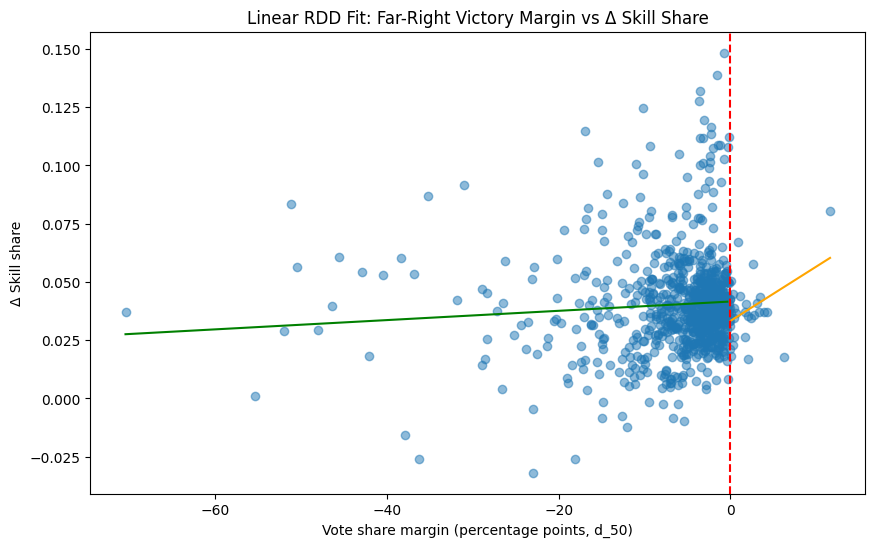

In [41]:
import statsmodels.api as sm

# ── Fit simple linear RDD model (separate slopes each side of cutoff) ──
df_rdd_clean['d_50_x_treat'] = df_rdd_clean['d_50'] * df_rdd_clean['treat']
X = sm.add_constant(df_rdd_clean[['d_50', 'treat', 'd_50_x_treat']])
model1 = sm.OLS(df_rdd_clean['delta_skill_share'], X).fit()

# ── Predict fitted lines on each side of the cutoff ──
cutoff = 0.
x_vals = np.linspace(df_rdd_clean['d_50'].min(), df_rdd_clean['d_50'].max(), 200)

x_left = pd.DataFrame({'d_50': x_vals[x_vals <= cutoff], 'treat': 0})
x_left['d_50_x_treat'] = x_left['d_50'] * x_left['treat']
x_left = sm.add_constant(x_left, has_constant='add')

x_right = pd.DataFrame({'d_50': x_vals[x_vals > cutoff], 'treat': 1})
x_right['d_50_x_treat'] = x_right['d_50'] * x_right['treat']
x_right = sm.add_constant(x_right, has_constant='add')

y_pred_left = model1.predict(x_left)
y_pred_right = model1.predict(x_right)

# ── Plot ──
plt.figure(figsize=(10, 6))
plt.scatter(df_rdd_clean['d_50'], df_rdd_clean['delta_skill_share'], alpha=0.5)
plt.plot(x_left['d_50'], y_pred_left, color='green')
plt.plot(x_right['d_50'], y_pred_right, color='orange')
plt.axvline(cutoff, color='red', linestyle='--')
plt.title('Linear RDD Fit: Far-Right Victory Margin vs Δ Skill Share')
plt.xlabel('Vote share margin (percentage points, d_50)')
plt.ylabel('Δ Skill share')
plt.show()

# Select Bandwidth

In [42]:
from rdrobust import rdbwselect, rdrobust

# Optimal bandwidth selection

# Uses the running variable (d_50) and outcome (delta_skill_share)
# c=0 -> cutoff is at 0 (already centered)
bw_result = rdbwselect(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0
)
print(bw_result)

Call: rdbwselect
Number of Observations:                   837
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

       h (left)  h (right)  b (left)  b (right)
mserd     1.648      1.648     2.757      2.757


In [43]:
# RD treatment effect estimation using the selected bandwidth

# rdrobust automatically selects its own optimal bandwidth internally (MSE-optimal by default),
# so you don't strictly need to feed bw_result in manually — but you can inspect/compare
rd_result = rdrobust(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0
)
print(rd_result)

Call: rdrobust

Sharp RD estimates using local polynomial regression.

Number of Observations:                   837
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations           811         26
Number of Unique Obs.            811         26
Number of Effective Obs.         147         12
Bandwidth Estimation           1.648      1.648
Bandwidth Bias                 2.757      2.757
rho (h/b)                      0.598      0.598

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
-------------------------------------------------------------------------
Conventional      -0.011    0.009   -1.293   1.960e-01    [-0.028, 0.006]
Robust                 -        -   -1.333   1.

In [44]:
# Restrict sample to the MSE-optimal bandwidth from rdbwselect
bw = 1.648 # h (left) = h (right) from rdbwselect output

In [45]:
df_rdd_bw = df_rdd_clean[
    (df_rdd_clean['d_50'] >= -bw) & (df_rdd_clean['d_50'] <= bw)
].copy()

print(f"N observations within bandwidth: {len(df_rdd_bw)}")
print(f"N treated within bandwidth: {df_rdd_bw['treat'].sum()}")

N observations within bandwidth: 159
N treated within bandwidth: 12


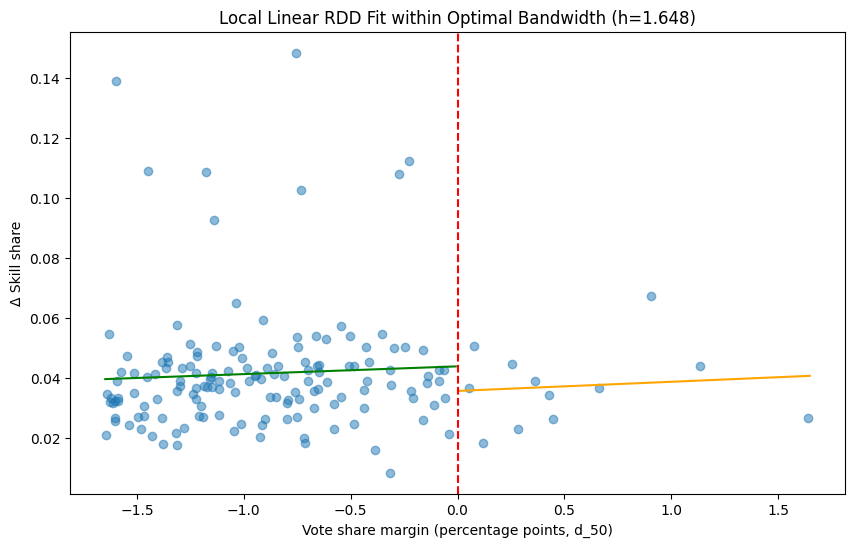

In [46]:
import statsmodels.api as sm

# ── Fit local linear RDD model WITHIN the bandwidth (matches rdrobust's p=1 local-linear spec) ──
df_rdd_bw['d_50_x_treat'] = df_rdd_bw['d_50'] * df_rdd_bw['treat']
X = sm.add_constant(df_rdd_bw[['d_50', 'treat', 'd_50_x_treat']])
model_bw = sm.OLS(df_rdd_bw['delta_skill_share'], X).fit()

# ── Predict fitted lines on each side of the cutoff, within the bandwidth only ──
cutoff = 0.
x_vals = np.linspace(-bw, bw, 200)

x_left = pd.DataFrame({'d_50': x_vals[x_vals <= cutoff], 'treat': 0})
x_left['d_50_x_treat'] = x_left['d_50'] * x_left['treat']
x_left = sm.add_constant(x_left, has_constant='add')

x_right = pd.DataFrame({'d_50': x_vals[x_vals > cutoff], 'treat': 1})
x_right['d_50_x_treat'] = x_right['d_50'] * x_right['treat']
x_right = sm.add_constant(x_right, has_constant='add')

y_pred_left = model_bw.predict(x_left)
y_pred_right = model_bw.predict(x_right)

# ── Plot ──
plt.figure(figsize=(10, 6))
plt.scatter(df_rdd_bw['d_50'], df_rdd_bw['delta_skill_share'], alpha=0.5)
plt.plot(x_left['d_50'], y_pred_left, color='green')
plt.plot(x_right['d_50'], y_pred_right, color='orange')
plt.axvline(cutoff, color='red', linestyle='--')
plt.title(f'Local Linear RDD Fit within Optimal Bandwidth (h={bw})')
plt.xlabel('Vote share margin (percentage points, d_50)')
plt.ylabel('Δ Skill share')
plt.show()

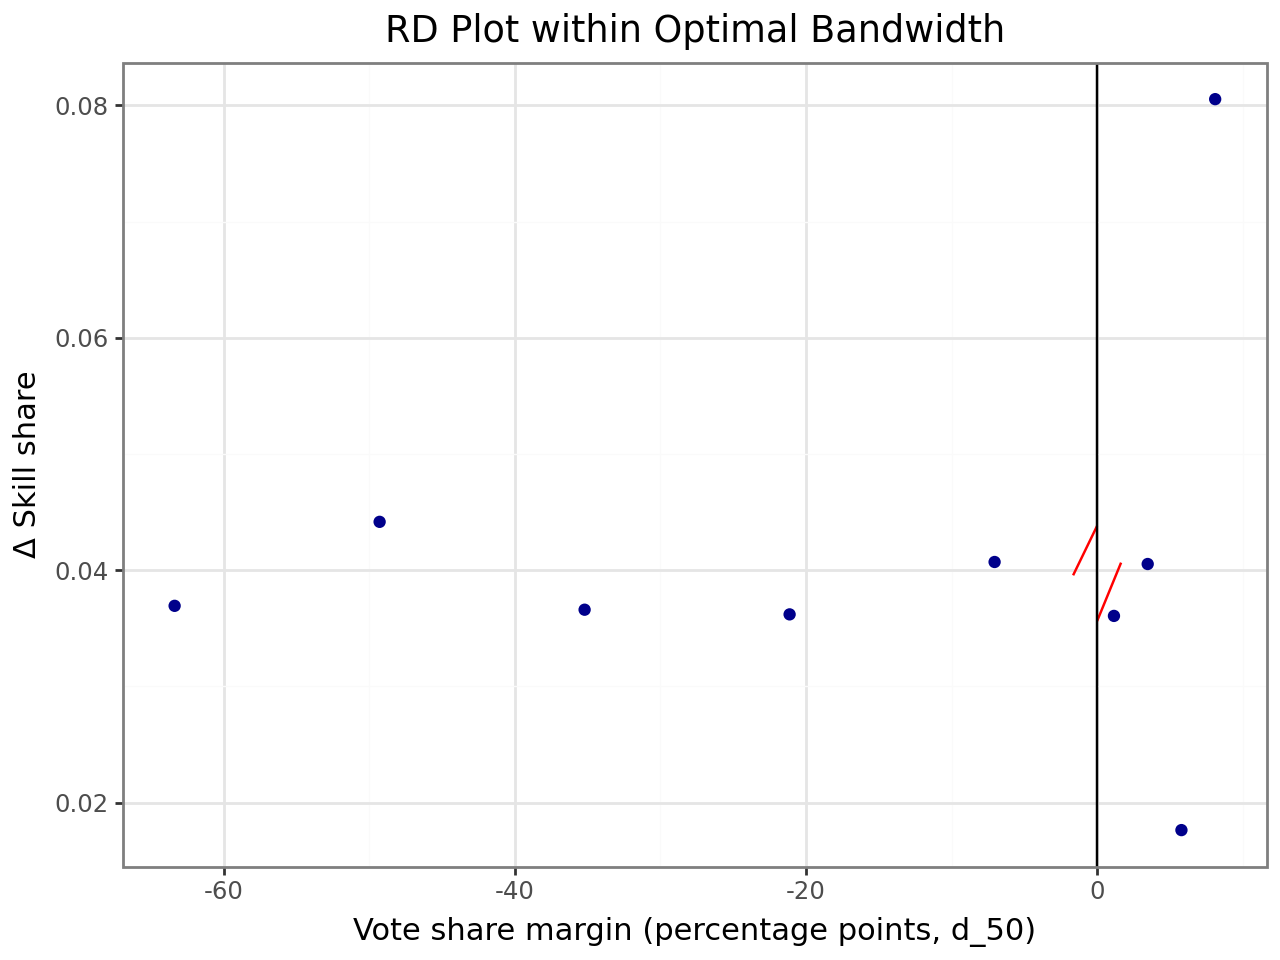

Call: rdplot
Number of Observations:                   837
Kernel:                               Uniform
Polynomial Order Est. (p):                  1

                                Left      Right
------------------------------------------------
Number of Observations           811         26
Number of Effective Obs          147         12
Bandwidth poly. fit (h)        1.648      1.648
Number of bins scale               1          1
Bins Selected                      5          5
Average Bin Length            14.084      2.318
Median Bin Length             14.084      2.318
IMSE-optimal bins                6.0        5.0
Mimicking Variance bins         12.0        4.0

Relative to IMSE-optimal:
Implied scale                  0.833        1.0
WIMSE variance weight          0.633        0.5
WIMSE bias weight              0.367        0.5

In [47]:
from rdrobust import rdplot

# ── Standard rdplot: automatically bins, fits local polynomial, and plots ──
# p=1 -> linear fit (matches your model_bw specification)
# This uses the FULL sample (df_rdd_clean), not just the bandwidth-restricted one --
# rdplot is a descriptive/diagnostic tool and typically shown on the wider sample,
# with the bandwidth from rdbwselect used only for the rdrobust estimation itself
rdplot(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0,
    p=1,
    h=bw,  # manually restrict to the rdbwselect bandwidth
    nbins=(5, 5),  # 5 bins left, 5 bins right
    title='RD Plot within Optimal Bandwidth',
    x_label='Vote share margin (percentage points, d_50)',
    y_label='Δ Skill share'
)

# Regress OLS naive

In [48]:
from statsmodels.formula.api import ols

In [49]:
# interaction term: allows the slope of d_50 to differ on each side of the cutoff ──
# Similar the specification in the plot (standard sharp-RDD practice)
model1 = ols('delta_skill_share ~ d_50 * treat', data=df_rdd_clean).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:      delta_skill_share   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     2.086
Date:                Tue, 18 Aug 2026   Prob (F-statistic):              0.101
Time:                        09:25:55   Log-Likelihood:                 2028.6
No. Observations:                 837   AIC:                            -4049.
Df Residuals:                     833   BIC:                            -4030.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0416      0.001     42.327      0.0

In [50]:
from rdrobust import rdrobust

# RD point estimate + confidence interval using rdrobust library
rd_result = rdrobust(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0,  # dont know 
    p=1,  # local linear, matches rdplot specification
    h=bw  # my rdwselect bandwidth which I used to restrict the sample for the linear regression above
)
print(rd_result)

Call: rdrobust

Sharp RD estimates using local polynomial regression.

Number of Observations:                   837
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                   Manual
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations           811         26
Number of Unique Obs.            811         26
Number of Effective Obs.         147         12
Bandwidth Estimation           1.648      1.648
Bandwidth Bias                 1.648      1.648
rho (h/b)                        1.0        1.0

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
-------------------------------------------------------------------------
Conventional      -0.011    0.009   -1.293   1.960e-01    [-0.028, 0.006]
Robust                 -        -   -0.304   7.

# diff in disc model

In [51]:
# Keep id columns + any column ending in a year >= 2006
id_cols = ["dep", "nomdep", "codecommune", "nomcommune"]
year_cols_keep = [c for c in df_edu.columns
                   if any(c.endswith(str(y)) for y in range(2006, 2024))]

df_edu = df_edu[id_cols + year_cols_keep]

In [52]:
# Claude AI code


# ══════════════════════════════════════════════════════════════════
# STEP 1: Build skill-share LEVELS at each offset relative to each election
# ══════════════════════════════════════════════════════════════════
# We need skill_share as a LEVEL (not yet a delta) for several years around
# each election, because deltas are computed afterward from pairs of levels:
#   - the "placebo" delta uses two PRE-election years (t-2, t-1)
#   - the "post" deltas use t-1 vs t+1, t+2, t+3
elections = [2008, 2014, 2020]
offsets   = [-2, -1, 1, 2, 3]     # -2,-1 = placebo pair; 1,2,3 = post-treatment
min_pop   = 50                     # same population screen you used before

def year_cols_exist(df, year):
    """
    Guard against requesting a year that doesn't exist in df_edu
    (e.g. 2020 + 3 = 2023, which may not be in the dataset yet).
    Checks that all 6 raw education columns needed for compute_skill_share()
    are present for that year before trying to use them.
    """
    needed = [f"nodiph{year}", f"suph{year}", f"bach{year}",
              f"nodipf{year}", f"bacf{year}", f"supf{year}"]
    return all(c in df.columns for c in needed)

rows = []
for election_year in elections:
    for k in offsets:
        y = election_year + k  # actual calendar year, e.g. 2014 + (-1) = 2013

        # Skip silently if this year isn't in df_edu (keeps the panel unbalanced
        # rather than crashing -- e.g. no t+3 data yet for the 2020 election)
        if not year_cols_exist(df_edu, y):
            continue

        # Compute skill share and population for this specific year
        share = compute_skill_share(df_edu, y)
        pop   = compute_total_pop(df_edu, y)

        # One row per commune, tagged with which election + which offset
        # this observation belongs to
        tmp = pd.DataFrame({
            "commune_id":       df_edu["codecommune"],
            "election_year":    election_year,
            "time_to_election": k,           # -2, -1, 1, 2, or 3
            "skill_share":      share,
            "pop":              pop,
        })
        rows.append(tmp)

# Stack every (election, offset) block into one long "levels" panel:
# one row per commune x election x offset
df_levels = pd.concat(rows, ignore_index=True)

# Apply the same data-quality filter as your original delta_skill_share code:
# communes with too few residents give unreliable skill-share estimates,
# so null them out rather than keep noisy values
df_levels.loc[df_levels["pop"] < min_pop, "skill_share"] = np.nan


# ══════════════════════════════════════════════════════════════════
# STEP 2: Reshape long -> wide (one row per commune x election,
# one column per offset) so we can subtract levels to build deltas
# ══════════════════════════════════════════════════════════════════
df_wide = df_levels.pivot_table(
    index=["commune_id", "election_year"],   # one row per commune-election
    columns="time_to_election",               # one column per offset (-2,-1,1,2,3)
    values="skill_share"
).reset_index()

# pivot_table leaves numeric column names (-2, -1, 1, 2, 3);
# rename them to readable labels like "share_t-1", "share_t2", etc.
df_wide.columns = ["commune_id", "election_year"] + [f"share_t{c}" for c in df_wide.columns[2:]]


# ══════════════════════════════════════════════════════════════════
# STEP 3: Build deltas from the levels
# ══════════════════════════════════════════════════════════════════
# PLACEBO delta: change in skill share BEFORE the election happened
# (t-1 minus t-2). If the RD design is valid, this should show NO jump
# at the 50% threshold -- this is the diff-in-disc baseline.
df_wide["delta_-1"] = df_wide["share_t-1"] - df_wide["share_t-2"]

# POST-treatment deltas: change in skill share AFTER the election,
# always measured relative to the same t-1 baseline, so all deltas
# are comparable on the same starting point.
for k in [1, 2, 3]:
    col = f"share_t{k}"
    if col in df_wide.columns:      # guards against missing t+3 for 2020
        df_wide[f"delta_{k}"] = df_wide[col] - df_wide["share_t-1"]


# ══════════════════════════════════════════════════════════════════
# STEP 4: Melt wide -> long "event panel"
# ══════════════════════════════════════════════════════════════════
# One row per commune x election x period, with a single "delta" column.
# This is the shape rdrobust needs: we'll loop over `period` and run
# a separate RD regression on each subset.
delta_cols = [c for c in df_wide.columns if c.startswith("delta_")]
df_event = df_wide.melt(
    id_vars=["commune_id", "election_year"],
    value_vars=delta_cols,
    var_name="period", value_name="delta"
)
# "delta_-1" -> -1, "delta_2" -> 2, etc. (period becomes an integer:
# -1 = placebo, 1/2/3 = years after the election)
df_event["period"] = df_event["period"].str.replace("delta_", "").astype(int)


# ══════════════════════════════════════════════════════════════════
# STEP 5: Attach the RD running variable (d_50) and treatment status
# ══════════════════════════════════════════════════════════════════
# d_50 and treat don't vary by period -- they're properties of the
# commune-election pair (the electoral outcome), so we pull them once
# from your existing RDD dataframe and merge them onto every period-row.
df_run = (df_rdd_clean[["code_commune", "election_year", "d_50", "treat"]]
          .drop_duplicates(subset=["code_commune", "election_year"]))

df_event = df_event.merge(
    df_run, left_on=["commune_id", "election_year"],
    right_on=["code_commune", "election_year"], how="inner"
).dropna(subset=["delta", "d_50"])  # drop rows missing either outcome or running var

In [53]:
results = []
for t in sorted(df_event["period"].unique()):
    sub = df_event[df_event["period"] == t]
    res = rdrobust(y=sub["delta"], x=sub["d_50"], c=0, p=1)
    results.append({
        "period": t,
        "coef":   res.coef.iloc[-1, 0],   # last row = "Robust" bias-corrected estimate
        "se":     res.se.iloc[-1, 0],
        "ci_l":   res.ci.iloc[-1, 0],
        "ci_u":   res.ci.iloc[-1, 1],
        "n":      sum(res.N),              # <- fixed: builtin sum(), not .sum()
        "bw":     res.bws.iloc[0, 0],
    })

df_results = pd.DataFrame(results).sort_values("period")
print(df_results)

   period      coef        se      ci_l      ci_u    n        bw
0      -1 -0.003753  0.002319 -0.008298  0.000792  837  1.307936
1       1 -0.007506  0.004588 -0.016499  0.001487  837  1.307487
2       2 -0.011203  0.006843 -0.024616  0.002209  837  1.308438
3       3 -0.007887  0.016348 -0.039928  0.024155  552  0.852528


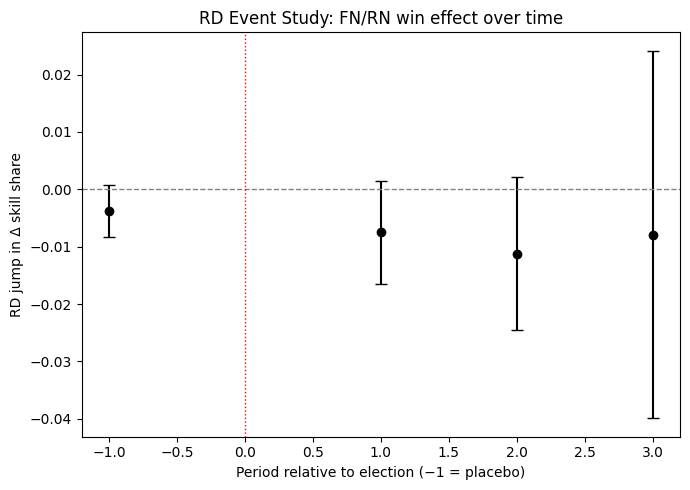

In [54]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7,5))
ax.errorbar(df_results["period"], df_results["coef"],
            yerr=[df_results["coef"]-df_results["ci_l"], df_results["ci_u"]-df_results["coef"]],
            fmt='o', capsize=4, color="black")
ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.axvline(0, color="red", linestyle=":", linewidth=1)  # election happens between -1 and +1
ax.set_xlabel("Period relative to election (−1 = placebo)")
ax.set_ylabel("RD jump in Δ skill share")
ax.set_title("RD Event Study: FN/RN win effect over time")
plt.tight_layout()
plt.show()

In [55]:
import statsmodels.formula.api as smf

# bw = your rdbwselect bandwidth from earlier
df_pooled = df_event[df_event["d_50"].abs() <= bw].copy()
df_pooled["period"] = df_pooled["period"].astype(str)  # categorical

model = smf.ols(
    "delta ~ C(period, Treatment(reference='-1')) * treat * d_50",
    data=df_pooled
).fit(cov_type="cluster", cov_kwds={"groups": df_pooled["commune_id"]})

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  delta   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.560
Method:                 Least Squares   F-statistic:                     74.10
Date:                Tue, 18 Aug 2026   Prob (F-statistic):           6.13e-53
Time:                        09:25:56   Log-Likelihood:                 2131.5
No. Observations:                 595   AIC:                            -4231.
Df Residuals:                     579   BIC:                            -4161.
Df Model:                          15                                         
Covariance Type:              cluster                                         
                                                           coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------